In [73]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
import keras
from keras.layers import Dense, Dropout, Input
from keras.models import Sequential

In [74]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [75]:
df = pd.read_csv('/content/drive/MyDrive/CSE475/heart_disease_uci.csv')
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [77]:
df_copy = df.copy()

In [78]:
duplicate = df[df.duplicated()]
duplicate.count()

,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0


In [79]:
df.isnull().sum()

,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


In [80]:
# FOR NUMERIC COLUMNS
df['trestbps'] = df['trestbps'].fillna(df['trestbps'].mean())

df['chol'] = df['chol'].fillna(df['chol'].mean())

df['thalch'] = df['thalch'].fillna(df['thalch'].mean())

df['oldpeak'] = df['oldpeak'].fillna(df['oldpeak'].mean())

df['ca'] = df['ca'].fillna(df['ca'].mean())

In [81]:
# FOR NUMERIC CATEGORICAL
df['fbs'] = df['fbs'].fillna(df['fbs'].mode()[0])

df['restecg'] = df['restecg'].fillna(df['restecg'].mode()[0])

df['exang'] = df['exang'].fillna(df['exang'].mode()[0])

df['slope'] = df['slope'].fillna(df['slope'].mode()[0])

df['thal'] = df['thal'].fillna(df['thal'].mode()[0])

/tmp/ipython-input-1015322270.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['fbs'] = df['fbs'].fillna(df['fbs'].mode()[0])
/tmp/ipython-input-1015322270.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['exang'] = df['exang'].fillna(df['exang'].mode()[0])


In [82]:
df.isnull().sum()

,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0


In [83]:
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.300000,downsloping,0.000000,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.500000,flat,3.000000,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.600000,flat,2.000000,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.500000,downsloping,0.000000,normal,0
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.400000,upsloping,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.000000,flat,0.676375,normal,1
916,917,62,Male,VA Long Beach,typical angina,132.132404,139.0,False,st-t abnormality,137.545665,False,0.878788,flat,0.676375,normal,0
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.000000,flat,0.676375,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,132.132404,385.0,True,lv hypertrophy,137.545665,False,0.878788,flat,0.676375,normal,0


In [85]:
print(model['sex'].unique())
print(model['dataset'].unique())
print(model['cp'].unique())
print(model['restecg'].unique())
print(model['slope'].unique())
print(model['thal'].unique())

['Male' 'Female']
['Cleveland' 'Hungary' 'Switzerland' 'VA Long Beach']
['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']
['lv hypertrophy' 'normal' 'st-t abnormality']
['downsloping' 'flat' 'upsloping']
['fixed defect' 'normal' 'reversable defect']


In [88]:
model = pd.get_dummies(model, columns=['sex', 'fbs', 'exang', 'dataset', 'cp', 'restecg', 'slope', 'thal'],dtype=int)
model

,age,trestbps,chol,thalch,oldpeak,ca,num,sex_Female,sex_Male,fbs_False,...,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
0,63,145.000000,233.0,150.000000,2.300000,0.000000,0,0,1,0,...,1,1,0,0,1,0,0,1,0,0
1,67,160.000000,286.0,108.000000,1.500000,3.000000,2,0,1,1,...,0,1,0,0,0,1,0,0,1,0
2,67,120.000000,229.0,129.000000,2.600000,2.000000,1,0,1,1,...,0,1,0,0,0,1,0,0,0,1
3,37,130.000000,250.0,187.000000,3.500000,0.000000,0,0,1,1,...,0,0,1,0,1,0,0,0,1,0
4,41,130.000000,204.0,172.000000,1.400000,0.000000,0,1,0,1,...,0,1,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,127.000000,333.0,154.000000,0.000000,0.676375,1,1,0,0,...,0,0,0,1,0,1,0,0,1,0
916,62,132.132404,139.0,137.545665,0.878788,0.676375,0,0,1,1,...,1,0,0,1,0,1,0,0,1,0
917,55,122.000000,223.0,100.000000,0.000000,0.676375,2,0,1,0,...,0,0,0,1,0,1,0,1,0,0
918,58,132.132404,385.0,137.545665,0.878788,0.676375,0,0,1,0,...,0,1,0,0,0,1,0,0,1,0


# **EDA**

/tmp/ipython-input-708089550.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='num', palette='Set2')


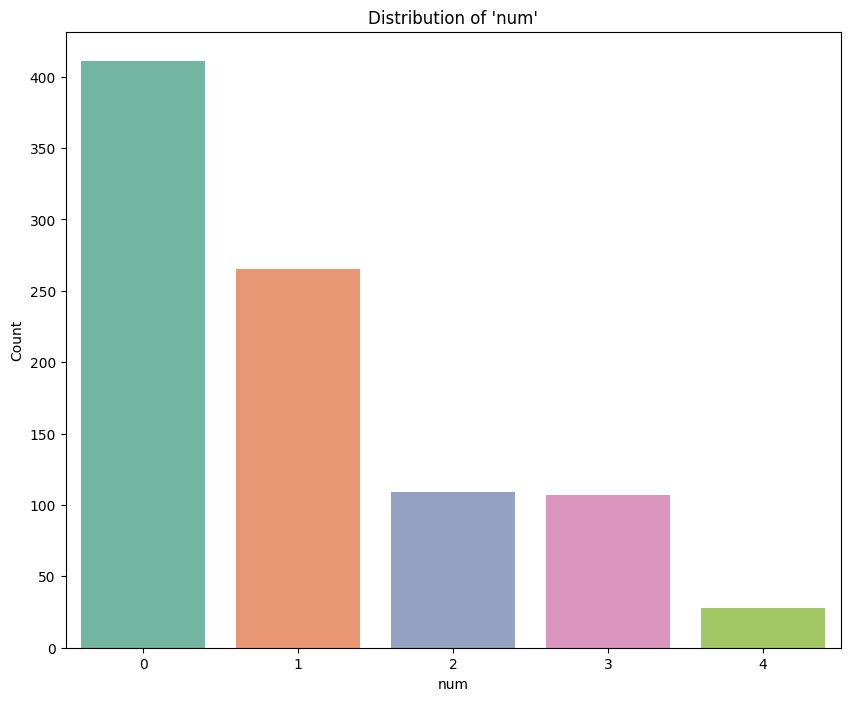

In [92]:
plt.figure(figsize=(10, 8))
sns.countplot(data=df, x='num', palette='Set2')
plt.title("Distribution of 'num'")
plt.ylabel('Count')
plt.show()

/tmp/ipython-input-483306614.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df, x='trestbps', palette='Set2')


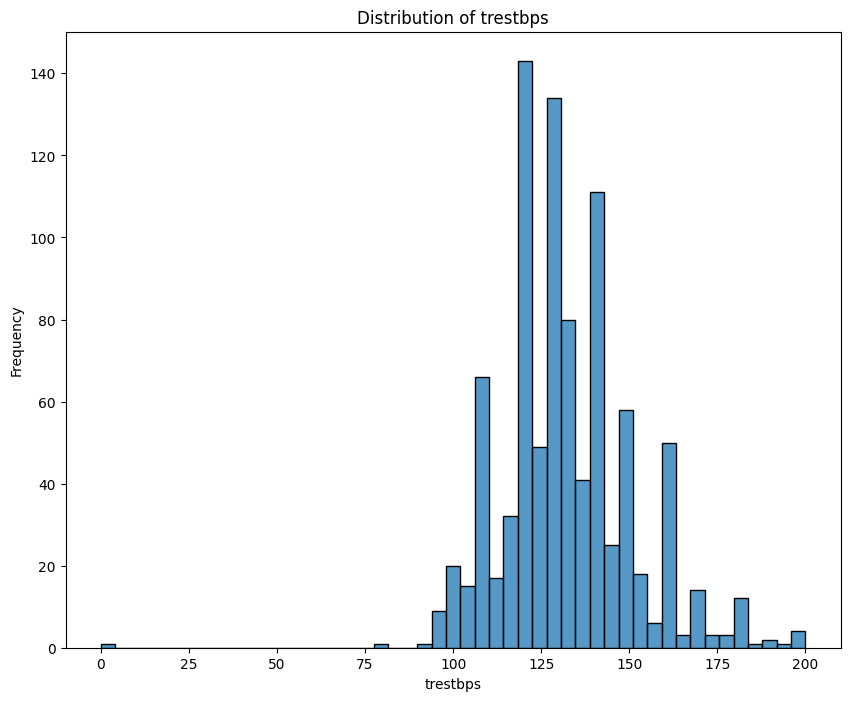

In [95]:
plt.figure(figsize=(10, 8))
sns.histplot(data=df, x='trestbps', palette='Set2')
plt.title("Distribution of trestbps")
plt.ylabel('Frequency')
plt.show()

In [96]:
corr = model.corr()
corr

,age,trestbps,chol,thalch,oldpeak,ca,num,sex_Female,sex_Male,fbs_False,...,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
age,1.000000,0.235253,-0.084499,-0.353471,0.248082,0.204139,0.339596,-0.056889,0.056889,-0.219915,...,0.032032,0.145652,-0.231296,0.137748,0.138352,-0.066460,-0.011606,0.020384,-0.131861,0.131164
trestbps,0.235253,1.000000,0.088290,-0.104616,0.160268,0.051940,0.116225,-0.001073,0.001073,-0.148398,...,0.045030,0.056598,-0.112763,0.081835,-0.003784,0.064115,-0.067790,0.004304,-0.076348,0.079966
chol,-0.084499,0.088290,1.000000,0.226325,0.045498,0.017544,-0.228238,0.193782,-0.193782,-0.089718,...,0.016716,0.181171,-0.040624,-0.134289,-0.081019,0.050578,-0.005950,-0.031051,0.087066,-0.077171
thalch,-0.353471,-0.104616,0.226325,1.000000,-0.149630,-0.140644,-0.351055,0.177135,-0.177135,0.030271,...,0.099862,0.120727,0.014809,-0.141289,-0.082113,-0.239367,0.311700,-0.049050,0.107166,-0.089178
oldpeak,0.248082,0.160268,0.045498,-0.149630,1.000000,0.178886,0.421907,-0.102733,0.102733,-0.050344,...,0.037266,0.093778,-0.114521,0.046137,0.327868,-0.064520,-0.129151,0.029517,-0.157715,0.154125
ca,0.204139,0.051940,0.017544,-0.140644,0.178886,1.000000,0.321404,-0.062058,0.062058,-0.080067,...,-0.029784,0.095703,-0.083995,0.006418,-0.014947,0.097101,-0.097053,0.053664,-0.159045,0.142608
num,0.339596,0.116225,-0.228238,-0.351055,0.421907,0.321404,1.000000,-0.259342,0.259342,-0.129539,...,-0.055896,0.075099,-0.168309,0.131698,0.178142,0.031161,-0.142565,0.105679,-0.310862,0.278313
sex_Female,-0.056889,-0.001073,0.193782,0.177135,-0.102733,-0.062058,-0.259342,1.000000,-1.000000,0.075370,...,0.003668,0.048613,0.013001,-0.065599,-0.066305,-0.046483,0.091201,-0.069688,0.153255,-0.127775
sex_Male,0.056889,0.001073,-0.193782,-0.177135,0.102733,0.062058,0.259342,-1.000000,1.000000,-0.075370,...,-0.003668,-0.048613,-0.013001,0.065599,0.066305,0.046483,-0.091201,0.069688,-0.153255,0.127775
fbs_False,-0.219915,-0.148398,-0.089718,0.030271,-0.050344,-0.080067,-0.129539,0.075370,-0.075370,1.000000,...,-0.043298,-0.081533,0.167536,-0.124189,-0.054840,-0.019472,0.054688,-0.071233,0.064647,-0.031461


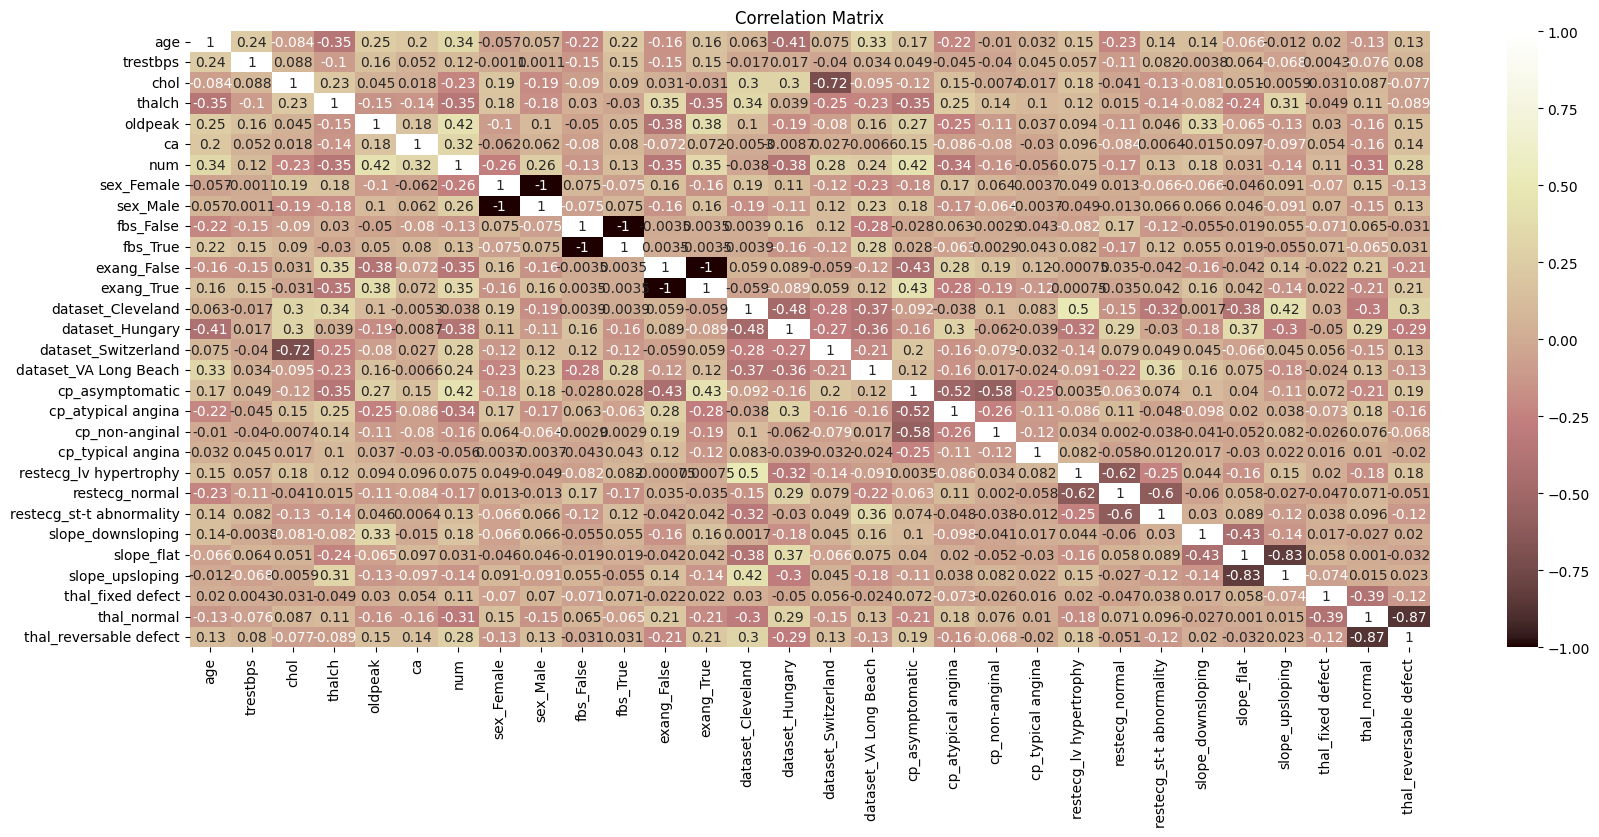

In [99]:
plt.figure(figsize=(20,8))
sns.heatmap(corr, annot=True, cmap='pink')
plt.title('Correlation Matrix')
plt.show()

# **SVM**

In [100]:
model = df.drop("id", axis=1)

In [101]:
X=model.drop(columns=['num'])
Y=model['num']

In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [103]:
from sklearn.svm import SVC
model = SVC(kernel='linear', random_state=42)
model.fit(X_train, y_train)

SVC(kernel='linear', random_state=42)

In [104]:
y_pred = model.predict(X_test)
print(y_pred)

[0 0 1 2 1 0 0 3 0 0 1 1 1 1 1 0 0 1 0 1 0 0 3 1 1 3 1 0 0 0 0 0 0 1 0 0 0
 1 0 0 1 0 1 0 0 1 1 3 0 0 0 0 0 1 0 0 2 0 3 1 0 0 1 3 0 1 0 1 1 0 3 0 1 0
 0 0 0 0 0 0 0 1 0 0 3 3 1 3 0 2 1 2 0 0 0 1 0 3 0 0 1 2 1 1 0 0 1 0 3 0 0
 2 1 0 0 0 1 0 1 0 0 1 0 2 1 0 1 0 1 0 0 0 0 0 1 0 1 3 1 0 3 3 0 1 1 1 3 0
 0 1 1 1 2 0 0 0 0 1 3 0 1 3 1 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 0 2 0 1 1]


In [105]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Calculate precision
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)

# Calculate recall (sensitivity)
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall:", recall)

# Calculate F1-score
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1-Score:", f1)

Accuracy: 0.5489130434782609
Precision: 0.4952374500079196
Recall: 0.5489130434782609
F1-Score: 0.5088807154811708


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# **DT**

In [106]:
dtree = DecisionTreeClassifier()
dtree = dtree.fit(X_train, y_train)

[Text(0.43200087547302246, 0.975, 'cp_asymptomatic <= 0.5\ngini = 0.683\nsamples = 736\nvalue = [336.0, 211.0, 84.0, 81.0, 24.0]'),
 Text(0.11639404296875, 0.925, 'chol <= 50.0\ngini = 0.439\nsamples = 339\nvalue = [247.0, 53.0, 17.0, 17.0, 5.0]'),
 Text(0.27419745922088623, 0.95, 'True  '),
 Text(0.0361328125, 0.875, 'thalch <= 96.5\ngini = 0.743\nsamples = 39\nvalue = [11, 13, 8, 6, 1]'),
 Text(0.0322265625, 0.825, 'gini = 0.0\nsamples = 3\nvalue = [0, 0, 0, 3, 0]'),
 Text(0.0400390625, 0.825, 'trestbps <= 122.5\ngini = 0.719\nsamples = 36\nvalue = [11, 13, 8, 3, 1]'),
 Text(0.015625, 0.775, 'oldpeak <= -0.05\ngini = 0.52\nsamples = 14\nvalue = [3, 9, 0, 2, 0]'),
 Text(0.0078125, 0.725, 'cp_non-anginal <= 0.5\ngini = 0.375\nsamples = 4\nvalue = [3, 1, 0, 0, 0]'),
 Text(0.00390625, 0.675, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0, 0, 0]'),
 Text(0.01171875, 0.675, 'gini = 0.0\nsamples = 3\nvalue = [3, 0, 0, 0, 0]'),
 Text(0.0234375, 0.725, 'trestbps <= 47.5\ngini = 0.32\nsamples = 10

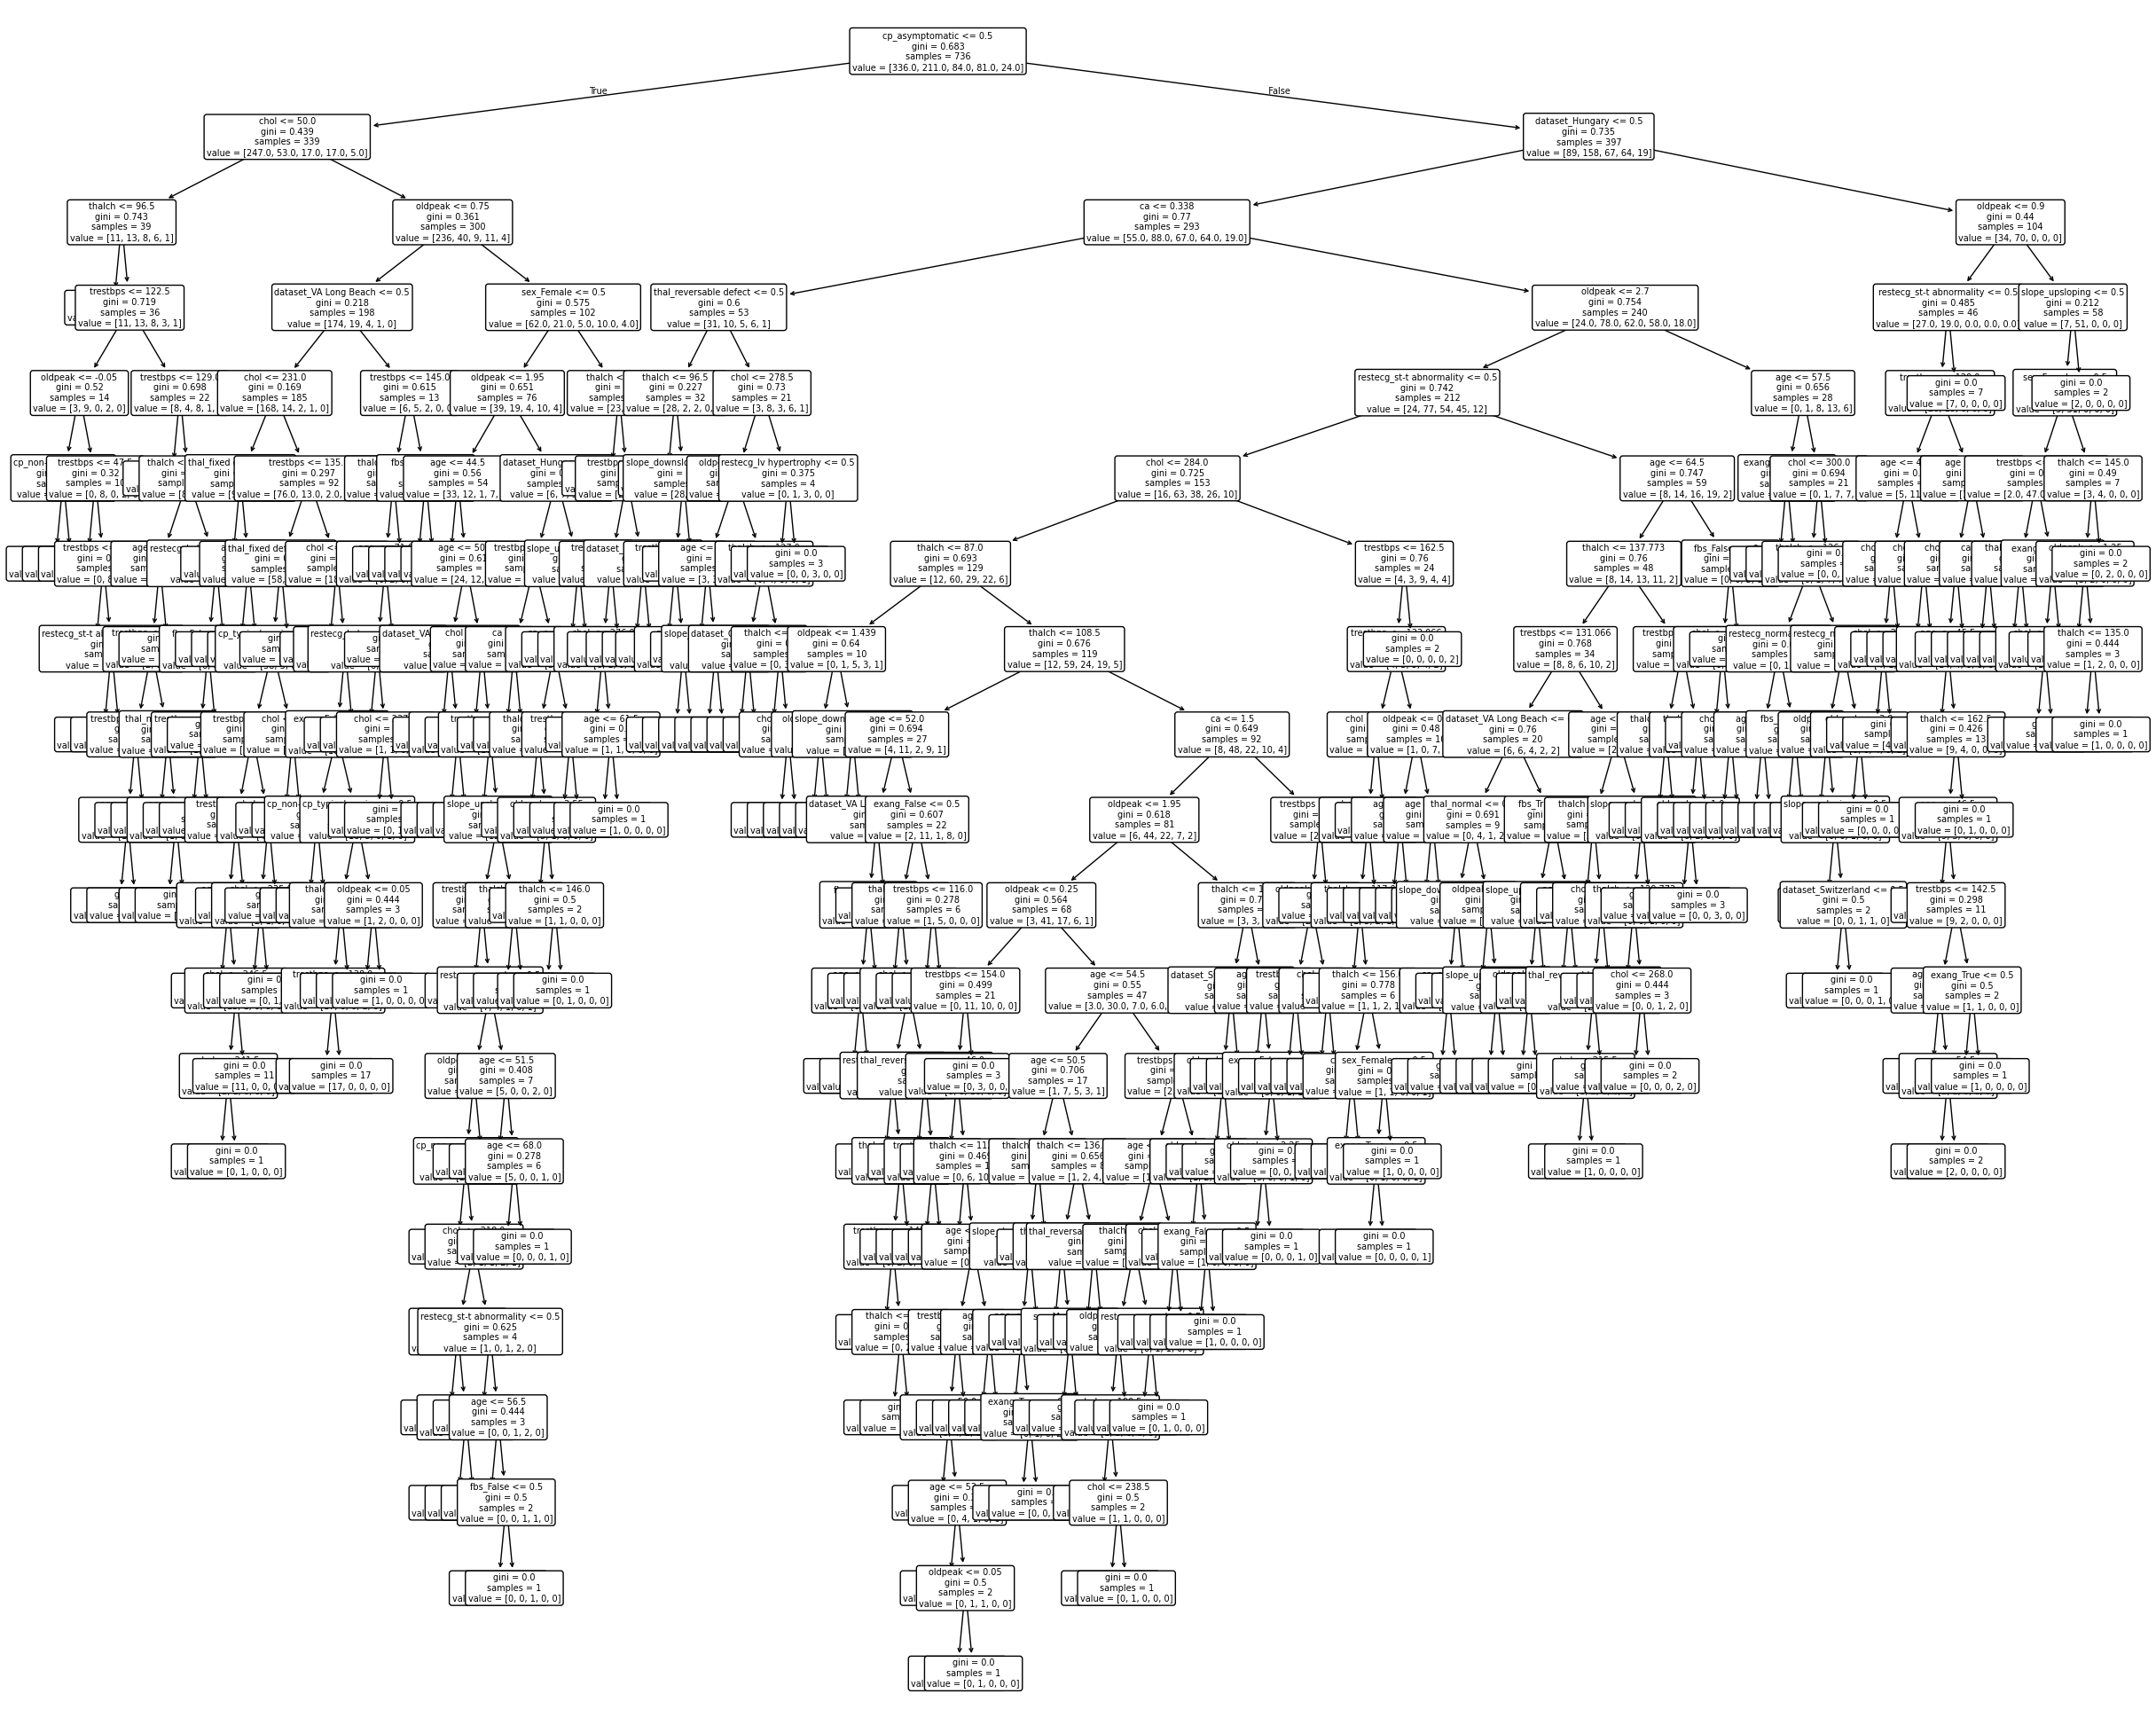

In [107]:
features = X.columns
fig = plt.figure(figsize=(30, 25))
tree.plot_tree(dtree, feature_names=features, rounded=True,fontsize=7)

In [108]:
y_pred_dt = dtree.predict(X_test)
print(y_pred_dt)

[0 0 1 1 1 0 0 1 0 0 1 1 1 1 1 3 0 0 0 1 0 1 3 1 0 3 1 0 3 0 0 0 0 4 0 3 1
 1 1 0 3 0 3 0 0 0 2 2 2 0 3 0 0 0 0 3 1 0 3 1 0 0 2 2 0 0 0 3 1 3 2 0 1 0
 0 0 0 1 0 0 0 3 0 0 1 3 1 3 1 3 3 0 0 0 0 0 0 1 0 0 0 3 0 1 1 0 1 1 2 0 2
 4 4 0 0 0 0 0 1 0 0 2 0 0 2 0 1 1 3 0 0 0 0 0 1 0 0 1 1 1 2 3 0 1 2 1 3 1
 0 2 1 1 2 3 0 0 1 1 2 0 1 2 1 0 1 2 0 1 0 1 1 0 0 0 1 1 0 1 2 2 4 0 1 1]


In [109]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", accuracy)

# Calculate precision
precision_dt = precision_score(y_test, y_pred_dt, average='weighted')
print("Precision:", precision)

# Calculate recall (sensitivity)
recall_dt = recall_score(y_test, y_pred_dt, average='weighted')
print("Recall:", recall)

# Calculate F1-score
f1_dt = f1_score(y_test, y_pred_dt, average='weighted')
print("F1-Score:", f1)

Accuracy: 0.5489130434782609
Precision: 0.4952374500079196
Recall: 0.5489130434782609
F1-Score: 0.5088807154811708


# **RF**

In [110]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [111]:
y_pred_rf = rf.predict(X_test)
y_pred_rf

array([0, 0, 1, 2, 0, 0, 0, 3, 0, 0, 1, 1, 1, 2, 1, 0, 0, 0, 0, 1, 0, 0,
       3, 1, 3, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 3, 0, 0, 0, 0, 1, 0, 2, 0,
       0, 1, 1, 0, 2, 0, 2, 0, 0, 1, 0, 3, 3, 0, 1, 1, 0, 0, 1, 3, 0, 2,
       0, 0, 1, 4, 2, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 2, 1, 3,
       1, 3, 1, 2, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 2, 0,
       0, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 2, 3, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 2, 1, 0, 1, 3, 1, 3, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 2, 3, 0, 1, 3, 1, 0, 0, 1, 0, 1, 0, 1, 3, 0, 0, 0, 0, 2,
       0, 1, 1, 0, 4, 0, 0, 1])

In [112]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", accuracy_rf)

# Calculate precision
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
print("Precision:", precision_rf)

# Calculate recall (sensitivity)
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
print("Recall (Sensitivity):", recall_rf)

# Calculate F1-score
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')
print("F1-Score:", f1_rf)

Accuracy: 0.5760869565217391
Precision: 0.5288825757575758
Recall (Sensitivity): 0.5760869565217391
F1-Score: 0.5414775067597357


# **NEURAL** **NETWORK**

In [114]:
print("shape of X_train",X_train.shape)
print("Shape of Y_train",y_train.shape)
print("Shape of x_test",X_test.shape)

shape of X_train (736, 29)
Shape of Y_train (736,)
Shape of x_test (184, 29)


In [122]:
model = Sequential()

model.add(Dense(64, input_dim=29, activation='relu'))
model.add(Dense(len(y_train.unique()), activation='softmax'))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,245 (8.77 KB)

 Trainable params: 2,245 (8.77 KB)

 Non-trainable params: 0 (0.00 B)

In [123]:
model.compile(loss = tf.keras.losses.sparse_categorical_crossentropy, optimizer = tf.keras.optimizers.Adam(), metrics = ['accuracy'])
model.fit(X_train, y_train, batch_size = 32, verbose = 2, epochs = 50)

Epoch 1/50
23/23 - 2s - 79ms/step - accuracy: 0.2636 - loss: 24.4107
Epoch 2/50
23/23 - 0s - 8ms/step - accuracy: 0.3655 - loss: 7.8108
Epoch 3/50
23/23 - 0s - 8ms/step - accuracy: 0.4130 - loss: 3.1703
Epoch 4/50
23/23 - 0s - 14ms/step - accuracy: 0.4579 - loss: 2.2661
Epoch 5/50
23/23 - 0s - 10ms/step - accuracy: 0.4810 - loss: 1.9059
Epoch 6/50
23/23 - 0s - 13ms/step - accuracy: 0.4864 - loss: 1.7159
Epoch 7/50
23/23 - 0s - 8ms/step - accuracy: 0.4810 - loss: 1.6093
Epoch 8/50
23/23 - 0s - 7ms/step - accuracy: 0.5095 - loss: 1.4463
Epoch 9/50
23/23 - 0s - 8ms/step - accuracy: 0.4959 - loss: 1.3948
Epoch 10/50
23/23 - 0s - 10ms/step - accuracy: 0.4891 - loss: 1.4744
Epoch 11/50
23/23 - 0s - 6ms/step - accuracy: 0.5014 - loss: 1.3531
Epoch 12/50
23/23 - 0s - 5ms/step - accuracy: 0.5177 - loss: 1.3075
Epoch 13/50
23/23 - 0s - 4ms/step - accuracy: 0.5679 - loss: 1.2464
Epoch 14/50
23/23 - 0s - 6ms/step - accuracy: 0.5707 - loss: 1.1261
Epoch 15/50
23/23 - 0s - 6ms/step - accuracy: 0.569

In [124]:
predict = model.predict(X_test)
predict = (predict > 0.5).astype(int).ravel()
print(predict)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0
 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0
 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0
 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0

In [125]:
from sklearn import metrics
import numpy as np

Y_prob_train = model.predict(X_train)
Y_pred_rand = np.argmax(Y_prob_train, axis=1)
pre = np.round(metrics.precision_score(y_train, Y_pred_rand, average='weighted')*100,2)
print('Precision : ', pre)
accu = np.round(metrics.accuracy_score(y_train, Y_pred_rand)*100,2)
print('Accuracy : ', accu)
ree = np.round(metrics.recall_score(y_train, Y_pred_rand, average='weighted')*100,2)
print('Recall : ', ree)
F = np.round(metrics.f1_score(y_train, Y_pred_rand, average='weighted')*100,2)
print('F1 score : ', F)
Auc = np.round(metrics.roc_auc_score(y_train, Y_prob_train, multi_class='ovr', average='weighted')*100,2)
print('AUC : ', Auc)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Precision :  62.03
Accuracy :  62.64
Recall :  62.64
F1 score :  59.15
AUC :  86.88


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [126]:
results = pd.DataFrame({
    'Model': ['SVM', 'Decision Tree','Random Forest', 'Neural Network'],
    'Accuracy': [accuracy, accuracy_dt, accuracy_rf, accu],
    'Precision': [precision, precision_dt, precision_rf, pre],
    'Recall': [recall, recall_dt, recall_rf, ree],
    'F1-Score': [f1, f1_dt, f1_rf, F]
})

display(results)

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.548913,0.495237,0.548913,0.508881
1,Decision Tree,0.532609,0.507128,0.532609,0.517859
2,Random Forest,0.576087,0.528883,0.576087,0.541478
3,Neural Network,62.640000,62.030000,62.640000,59.150000
